# 03 – Random Forest
Random Forest classifier for predicting hotel booking cancellations (MS26936130).
Uses the same train/test split as the Logistic Regression notebook (created in notebook 01).

In [13]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42

In [14]:
# load the train/test sets created in notebook 01 (same split for both models)
train = pd.read_csv("../outputs/train.csv")
test = pd.read_csv("../outputs/test.csv")

X_train = train.drop(columns=["is_canceled"])
y_train = train["is_canceled"]
X_test = test.drop(columns=["is_canceled"])
y_test = test["is_canceled"]

print(X_train.shape, X_test.shape)

(69767, 29) (17442, 29)


In [15]:
# text columns need one-hot encoding; numeric columns are used as they are
cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical:", cat_cols)
print("Numeric:", len(num_cols), "columns")

Categorical: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']
Numeric: 20 columns


## Baseline model
A Random Forest with default settings, as a starting point before tuning.
Categorical columns are one-hot encoded inside a pipeline, so the encoder is fitted on the training data only (no leakage). Rare categories (fewer than 50 bookings, e.g. small countries) are grouped together. No scaling is needed, because tree-based models are not affected by the scale of features.

In [16]:
# preprocessing: one-hot encode text columns, pass numeric columns through unchanged
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_cols),
    ("num", "passthrough", num_cols),
])

# full pipeline: preprocessing + Random Forest
rf_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

In [17]:
start = time.time()
rf_pipeline.fit(X_train, y_train)
print("Training time:", round(time.time() - start, 1), "s")

y_pred = rf_pipeline.predict(X_test)
y_prob = rf_pipeline.predict_proba(X_test)[:, 1]   # probability of "canceled"

print("Train accuracy:", round(accuracy_score(y_train, rf_pipeline.predict(X_train)), 4))
print("Test accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision     :", round(float(precision_score(y_test, y_pred)), 4))
print("Recall        :", round(recall_score(y_test, y_pred), 4))
print("F1-score      :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC       :", round(roc_auc_score(y_test, y_prob), 4))

Training time: 37.3 s
Train accuracy: 0.9969
Test accuracy : 0.8282
Precision     : 0.746
Recall        : 0.5692
F1-score      : 0.6457
ROC-AUC       : 0.8769


## Hyperparameter tuning
The baseline overfits (train accuracy 0.997 vs test accuracy 0.828) and misses about 43% of cancellations (recall 0.57). Hyperparameters are tuned with randomized search and stratified 3-fold cross-validation on the training set only, using F1-score as the selection metric because the classes are imbalanced. The test set is not used during tuning.

In [18]:
# hyperparameters to try ("model__" refers to the Random Forest step in the pipeline)
param_dist = {
    "model__n_estimators": [100, 200, 300],      # number of trees
    "model__max_depth": [10, 20, 30, None],      # maximum depth of each tree
    "model__min_samples_leaf": [1, 2, 5],        # minimum bookings in a leaf (limits overfitting)
    "model__max_features": ["sqrt", "log2"],     # features considered at each split
    "model__class_weight": [None, "balanced"],   # "balanced" gives more weight to cancellations
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    rf_pipeline, param_dist,
    n_iter=10,              # try 10 random combinations
    scoring="f1",           # choose the best by F1 on the validation folds
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

start = time.time()
search.fit(X_train, y_train)
print("Tuning time:", round(time.time() - start, 1), "s")
print("Best parameters:", search.best_params_)
print("Best CV F1:", round(search.best_score_, 4))

Tuning time: 569.7 s
Best parameters: {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': 'balanced'}
Best CV F1: 0.6768


## Tuned model: test-set evaluation
The best model from the search is evaluated once on the untouched test set.

In [19]:
def evaluate(model, X_train, y_train, X_test, y_test):
    """Print train accuracy and test metrics for a fitted classifier."""
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]   # probability of "canceled"
    results = {
        "Train accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }
    for name, value in results.items():
        print(f"{name:<15}: {float(value):.4f}")
    return results

# baseline metrics again (rf_pipeline is still the fitted baseline), stored for the comparison table
baseline_results = evaluate(rf_pipeline, X_train, y_train, X_test, y_test)

Train accuracy : 0.9969
Test accuracy  : 0.8282
Precision      : 0.7460
Recall         : 0.5692
F1-score       : 0.6457
ROC-AUC        : 0.8769


In [20]:
best_rf = search.best_estimator_   # already refit on the full training set
tuned_results = evaluate(best_rf, X_train, y_train, X_test, y_test)

Train accuracy : 0.8626
Test accuracy  : 0.8035
Precision      : 0.6183
Recall         : 0.7468
F1-score       : 0.6765
ROC-AUC        : 0.8735


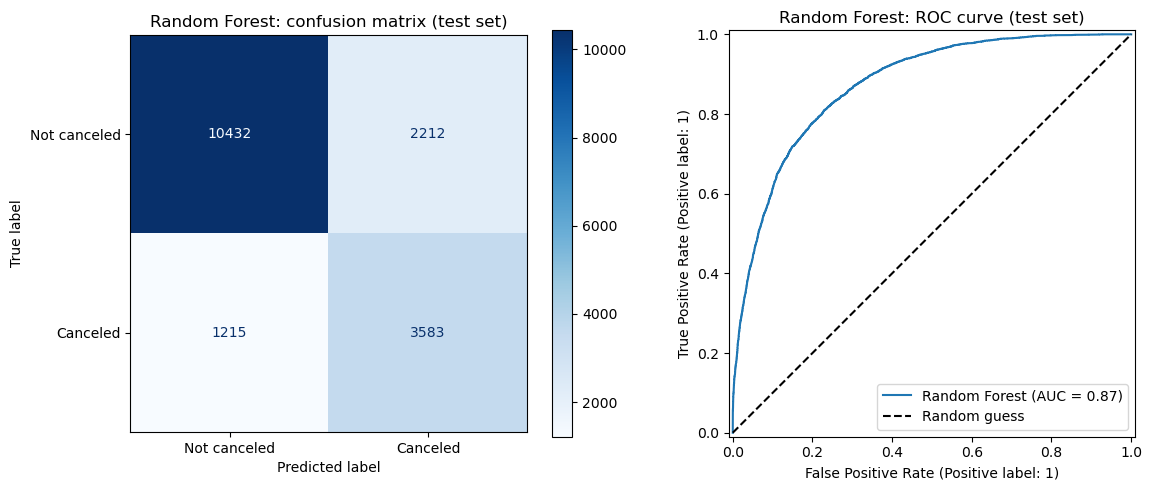

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    best_rf, X_test, y_test, display_labels=["Not canceled", "Canceled"],
    cmap="Blues", values_format="d", ax=axes[0])
axes[0].set_title("Random Forest: confusion matrix (test set)")

RocCurveDisplay.from_estimator(best_rf, X_test, y_test, ax=axes[1], name="Random Forest")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("Random Forest: ROC curve (test set)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/rf_confusion_roc.png", dpi=300, bbox_inches="tight")
plt.show()

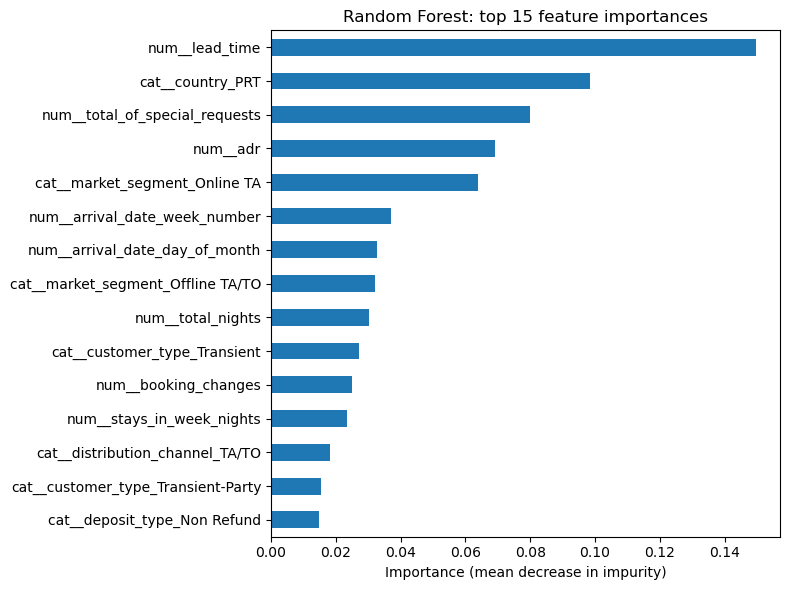

num__lead_time                        0.149644
cat__country_PRT                      0.098333
num__total_of_special_requests        0.079853
num__adr                              0.069154
cat__market_segment_Online TA         0.063785
num__arrival_date_week_number         0.037136
num__arrival_date_day_of_month        0.032830
cat__market_segment_Offline TA/TO     0.032174
num__total_nights                     0.030378
cat__customer_type_Transient          0.027198
num__booking_changes                  0.025056
num__stays_in_week_nights             0.023388
cat__distribution_channel_TA/TO       0.018317
cat__customer_type_Transient-Party    0.015511
cat__deposit_type_Non Refund          0.014745
dtype: float64

In [22]:
# which features does the forest rely on most?
feature_names = best_rf.named_steps["preprocess"].get_feature_names_out()
importances = pd.Series(best_rf.named_steps["model"].feature_importances_, index=feature_names)
top15 = importances.sort_values(ascending=False).head(15)

top15.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Random Forest: top 15 feature importances")
plt.xlabel("Importance (mean decrease in impurity)")
plt.tight_layout()
plt.savefig("../figures/rf_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

top15

In [ ]:
# save metrics so noteboo 04 can compare both models
results_df = pd.DataFrame([baseline_results, tuned_results],
                          index=["RF baseline", "RF tuned"])
results_df.to_csv("../outputs/rf_results.csv")
results_df.round(4)

,Train accuracy,Test accuracy,Precision,Recall,F1-score,ROC-AUC
RF baseline,0.9969,0.8282,0.7460,0.5692,0.6457,0.8769
RF tuned,0.8626,0.8035,0.6183,0.7468,0.6765,0.8735


**Tuned vs. Baseline Model**

Tuning reduced overfitting: the gap between training and test accuracy decreased from 16.9 to 5.9 percentage points (0.863 vs. 0.804). Recall increased from 0.57 to 0.75, and the F1-score improved from 0.65 to 0.68, mainly because `class_weight="balanced"` assigns greater weight to the canceled class. However, precision decreased from 0.75 to 0.62, resulting in more false alarms. For a hotel, missing a cancellation may be more costly than incorrectly predicting one, as it can lead to an empty room that could otherwise have been sold. Therefore, the tuned model is preferred despite its slightly lower accuracy. The ROC-AUC remained approximately 0.87, indicating that the model's ability to distinguish between canceled and non-canceled bookings remained similar.

**Confusion Matrix**

On the test set, the tuned model correctly identified 3,583 of the 4,798 canceled bookings and missed 1,215. It also incorrectly predicted cancellations for 2,212 of the 12,644 non-canceled bookings. These false alarms show the trade-off associated with the model's higher recall.

**Feature Importance**

The most important features are `lead_time`, guests from Portugal (`country_PRT`), the number of special requests, `adr` and the online travel agent market segment. This is consistent with the EDA, which showed that canceled bookings had a much longer median `lead_time` than non-canceled bookings. Date features such as `arrival_date_week_number` and `arrival_date_day_of_month` also contribute, which suggests seasonal patterns in cancellations. However, impurity-based feature importance can favour numerical features with many distinct values, so these rankings should be interpreted with care.

**Sensitivity check**

Before removing `required_car_parking_spaces` and `arrival_date_year`, the tuned model reached F1 = 0.707 and ROC-AUC = 0.897. Without them, F1 is 0.676 and ROC-AUC 0.873. The small drop shows that part of the earlier performance came from the likely-leaky parking feature; the new results are a more realistic estimate for predictions made at booking time.